# Pipeline Project

You will be using the provided data to create a machine learning model pipeline.

You must handle the data appropriately in your pipeline to predict whether an
item is recommended by a customer based on their review.
Note the data includes numerical, categorical, and text data.

You should ensure you properly train and evaluate your model.

## The Data

The dataset has been anonymized and cleaned of missing values.

There are 8 features for to use to predict whether a customer recommends or does
not recommend a product.
The `Recommended IND` column gives whether a customer recommends the product
where `1` is recommended and a `0` is not recommended.
This is your model's target/

The features can be summarized as the following:

- **Clothing ID**: Integer Categorical variable that refers to the specific piece being reviewed.
- **Age**: Positive Integer variable of the reviewers age.
- **Title**: String variable for the title of the review.
- **Review Text**: String variable for the review body.
- **Positive Feedback Count**: Positive Integer documenting the number of other customers who found this review positive.
- **Division Name**: Categorical name of the product high level division.
- **Department Name**: Categorical name of the product department name.
- **Class Name**: Categorical name of the product class name.

The target:
- **Recommended IND**: Binary variable stating where the customer recommends the product where 1 is recommended, 0 is not recommended.

## Load Data

In [1]:
import pandas as pd

# Load data
df = pd.read_csv(
    'data/reviews.csv',
)

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18442 entries, 0 to 18441
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Clothing ID              18442 non-null  int64 
 1   Age                      18442 non-null  int64 
 2   Title                    18442 non-null  object
 3   Review Text              18442 non-null  object
 4   Positive Feedback Count  18442 non-null  int64 
 5   Division Name            18442 non-null  object
 6   Department Name          18442 non-null  object
 7   Class Name               18442 non-null  object
 8   Recommended IND          18442 non-null  int64 
dtypes: int64(4), object(5)
memory usage: 1.3+ MB


,Clothing ID,Age,Title,Review Text,Positive Feedback Count,Division Name,Department Name,Class Name,Recommended IND
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,0,General,Dresses,Dresses,0
1,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",0,General Petite,Bottoms,Pants,1
2,847,47,Flattering shirt,This shirt is very flattering to all due to th...,6,General,Tops,Blouses,1
3,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",4,General,Dresses,Dresses,0
4,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,1,General Petite,Tops,Knits,1


## Preparing features (`X`) & target (`y`)

In [2]:
data = df

# separate features from labels
X = data.drop('Recommended IND', axis=1)
y = data['Recommended IND'].copy()

print('Labels:', y.unique())
print('Features:')
display(X.head())

Labels: [0 1]
Features:


,Clothing ID,Age,Title,Review Text,Positive Feedback Count,Division Name,Department Name,Class Name
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,0,General,Dresses,Dresses
1,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",0,General Petite,Bottoms,Pants
2,847,47,Flattering shirt,This shirt is very flattering to all due to th...,6,General,Tops,Blouses
3,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",4,General,Dresses,Dresses
4,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,1,General Petite,Tops,Knits


In [3]:
# Split data into train and test sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    shuffle=True,
    random_state=42,
    stratify=y
)

# Your Work

## Data Exploration

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

Max Age:  99


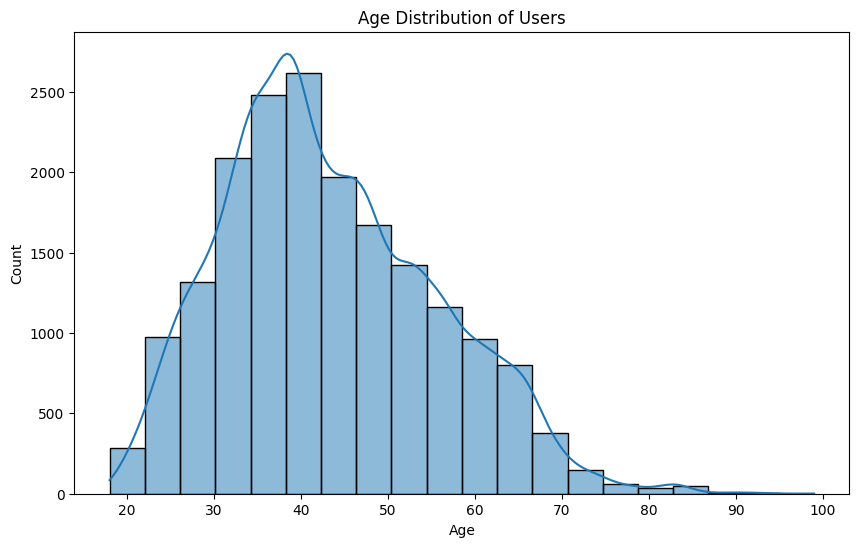

In [5]:
print("Max Age: ", df['Age'].max())

plt.figure(figsize=(10, 6))
sns.histplot(df['Age'], bins=20, kde=True)
plt.title('Age Distribution of Users')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

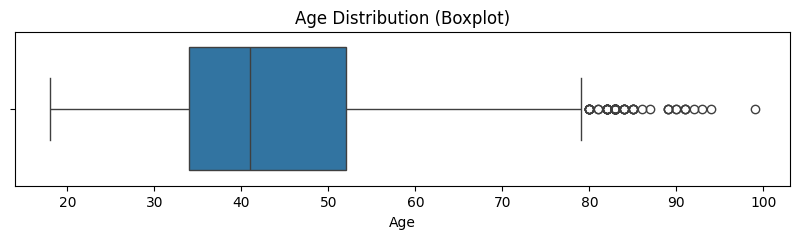

In [6]:
plt.figure(figsize=(10, 2))
sns.boxplot(x=df['Age'])
plt.title('Age Distribution (Boxplot)')
plt.show()

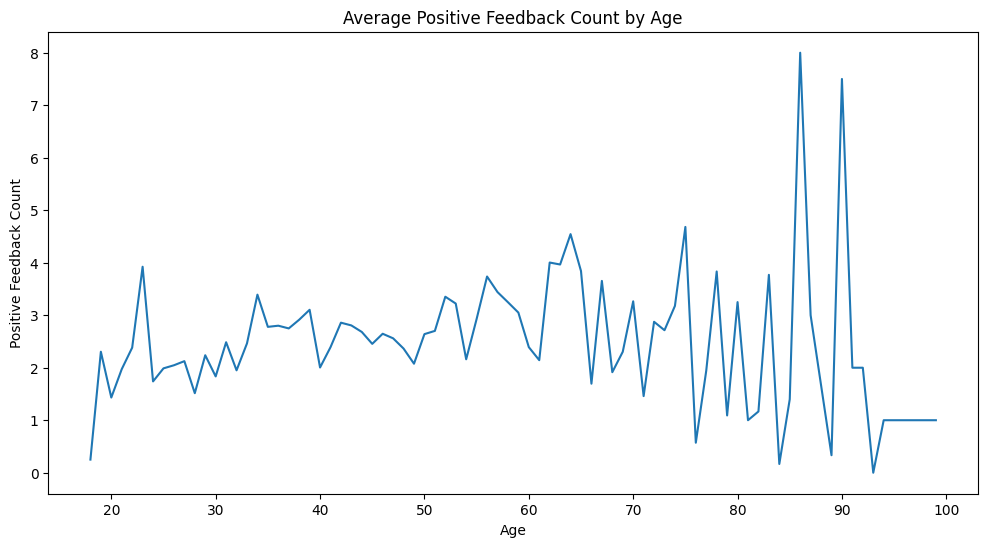

In [7]:
feedback_by_age = (
    df.groupby('Age')['Positive Feedback Count']
      .mean()
      .reset_index()
)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=feedback_by_age,
    x='Age',
    y='Positive Feedback Count'
)
plt.title('Average Positive Feedback Count by Age')
plt.show()

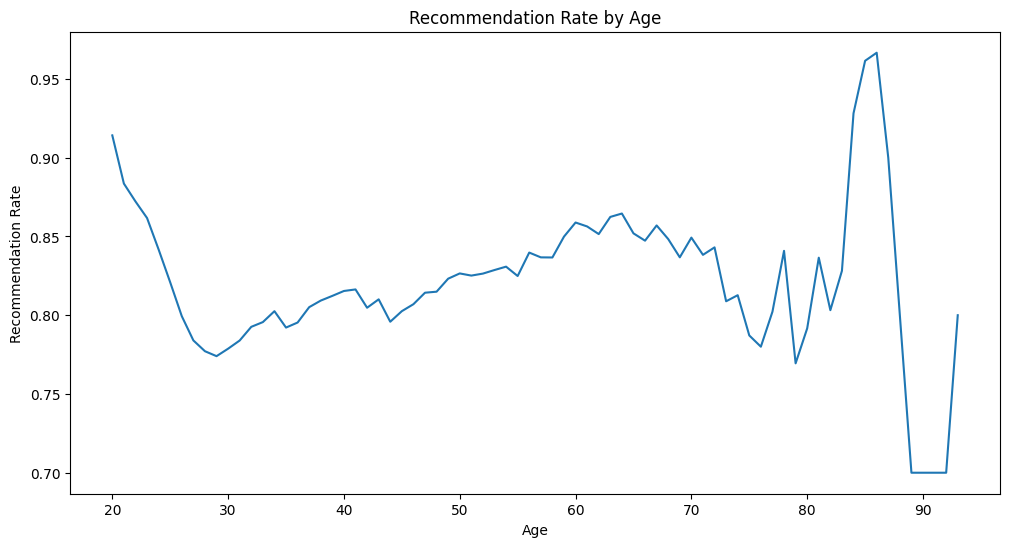

In [8]:
age_rec = (
    df.groupby('Age')['Recommended IND']
      .mean()
      .rolling(5, center=True)
      .mean()
)

plt.figure(figsize=(12,6))
age_rec.plot()
plt.ylabel('Recommendation Rate')
plt.title('Recommendation Rate by Age')
plt.show()

There are a number of outliers in the data for users between the ages 80 and 99 that have left a high volume of recommendations and positive feedback.

In [9]:
print("Raw recommendation value counts:\n",y.value_counts())
print("\nRecommencation Percentages:\n",y.value_counts(normalize = True))

Raw recommendation value counts:
 Recommended IND
1    15053
0     3389
Name: count, dtype: int64

Recommencation Percentages:
 Recommended IND
1    0.816235
0    0.183765
Name: proportion, dtype: float64



Recommendations look overwhelmingly positive, `81.6%`, as compared to `18.4%` unfavorable. This introduces a bias in the data that could prove problematic.

In [10]:
X['review_length'] = X['Review Text'].str.len()

print("Review Length describe data:\n", X['review_length'].describe())

Review Length describe data:
 count    18442.000000
mean       319.989535
std        141.953692
min          9.000000
25%        201.000000
50%        317.500000
75%        478.000000
max        508.000000
Name: review_length, dtype: float64


<Axes: xlabel='review_length', ylabel='Count'>

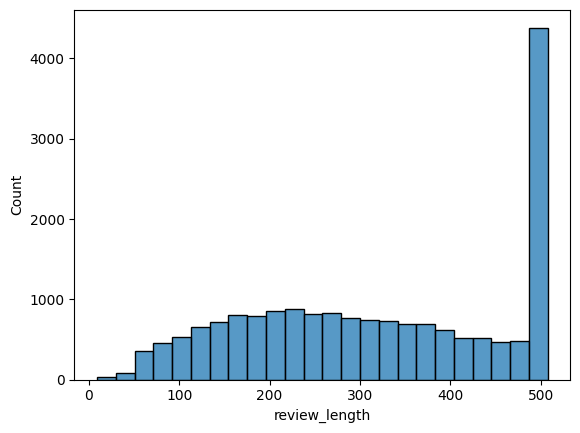

In [11]:
sns.histplot(X['review_length'])

In [12]:
X['Department Name'].value_counts()

Department Name
Tops        8713
Dresses     5371
Bottoms     3184
Jackets      879
Intimate     188
Trend        107
Name: count, dtype: int64

## Building Pipeline

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from pathlib import Path
import numpy as np
import spacy
import joblib

# install the spacy required language model quietly
!python -m spacy download en_core_web_sm --quiet


[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    shuffle=True,
    random_state=42,
    stratify=y
)

numberical_features=['Age', 'Positive Feedback Count', 'review_length']
categorical_features=['Division Name', 'Department Name', 'Class Name'] 
text_features= 'Review Text'

X_train = X_train.copy()
X_test  = X_test.copy()
X_train[text_features] = X_train['Title'] + ' ' + X_train['Review Text']
X_test[text_features]  = X_test['Title'] + ' ' + X_test['Review Text']

In [16]:
nlp = spacy.load("en_core_web_sm")

def preprocess_reviews(series):

    cleaned = []

    for doc in nlp.pipe(
        series.astype(str),
        batch_size=100
    ):

        tokens = [
            token.lemma_.lower()
            for token in doc
            if not token.is_stop
            and not token.is_punct
        ]

        cleaned.append(
            " ".join(tokens)
        )

    return cleaned

In [17]:
num_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

text_pipeline = Pipeline([
    ('spacy', FunctionTransformer(preprocess_reviews, validate=False)),
    ('tfidf', TfidfVectorizer(max_features=2000, ngram_range=(1, 2)))
])

preprocessor = ColumnTransformer(
    transformers=[('num', num_pipeline, numberical_features),
                  ('cat', cat_pipeline, categorical_features),
                  ('text', text_pipeline, text_features)]
)

pipeline = Pipeline([('preprocessor', preprocessor), 
                     ('classifier', LogisticRegression(max_iter=1000, random_state=42))])

## Training Pipeline

In [18]:
pipeline.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(pipeline.score(X_test, y_test)))

Accuracy on training set: 0.900


In [19]:
y_pred = pipeline.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.58      0.68       678
           1       0.91      0.97      0.94      3011

    accuracy                           0.90      3689
   macro avg       0.87      0.78      0.81      3689
weighted avg       0.90      0.90      0.89      3689



In [20]:
cm = confusion_matrix(y_test, y_pred)

print ("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[ 394  284]
 [  84 2927]]


This confirms the bias inherit in the model. It always catches postitives, Class 1, with a recall of .98. By comparison negatives, Class 0, are perdicted with a recal of .58. It does miss, but it's usually correct.

## Fine-Tuning Pipeline

In [21]:
param_grid = {
    'classifier__C': [
        0.01,
        0.1,
        1,
        10
    ],

    'classifier__class_weight': [
        None,
        'balanced'
    ]
}

In [23]:
grid_search_path = Path('grid_search.pkl')


if grid_search_path.is_file():
    print("Fine-Tuned GridSearchCV weights found.")
    grid_search = joblib.load('grid_search.pkl')
    
else: 
    print("Training Fine-Tuned GridSearchCV")
    grid_search = GridSearchCV(
        pipeline,
        param_grid,
        cv=5,
        scoring='f1_macro',
        n_jobs=1,
        verbose=2
    )
    
    grid_search.fit(X_train, y_train)
    
    # write out the weights because this can take some time to run
    joblib.dump(grid_search, 'grid_search.pkl')

Fine-Tuned GridSearchCV weights found.


In [24]:
print(f"Best Parameters: {grid_search.best_params_}")
tuned_y_pred = pipeline.predict(X_test)
print(classification_report(y_test, tuned_y_pred))

Best Parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}
              precision    recall  f1-score   support

           0       0.82      0.58      0.68       678
           1       0.91      0.97      0.94      3011

    accuracy                           0.90      3689
   macro avg       0.87      0.78      0.81      3689
weighted avg       0.90      0.90      0.89      3689



In [25]:
(y_pred == tuned_y_pred).mean()

1.0

In [30]:
cm = confusion_matrix(y_test, tuned_y_pred)

print ("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[ 394  284]
 [  84 2927]]


The results from fine-tuning the model using GridSearchCV with 5-fold cross-validation, interestingly the results were identical. The logistic regression model uses `max_iter=1000` and `random_state=42`, which defaults to `C=1` and `class_weight = None` and GridSearch determined that `C=1` and `class_weight = balanced` were best during cross-validation. From this it can be concluded that the original model configuration was already close to optimal for the dataset.
